# Lesson 5 Assignment: EDA using Pandas (Titanic Dataset)
**Student:** Meryulis Zambrano
**Course:** BIA - Introduction to AI

**Assignment - EDA using Pandas**

***Instructions***
- Clone a copy of the assignment notebook in Google Colab.
- **Complete the tasks by filling in the code where indicated by TODO comments. Put each task in a new cell.**
- Run each cell to ensure your code works correctly.
- Pay attention to the output of each cell and interpret the results.
- For visualisation tasks, make sure to label axes, add titles, and choose appropriate colour schemes.
- After completing all tasks, review your findings and include notes of your insights gained from the EDA process as markdown notes for assessments.


## Import necessary libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Task 1: Load the Titanic dataset
The file `Titanic-Dataset.csv` must be uploaded to the Colab session (folder `content`).

In [2]:
df = pd.read_csv('Titanic-Dataset.csv')
print(df.shape)   # (rows, columns)

(891, 12)


## Task 2: Inspect the data

In [3]:
# First 5 rows of the dataset
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# Last 5 rows of the dataset
df.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [5]:
# Data types of each column
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


In [6]:
# Summary statistics of the numerical columns
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**Notes:**
- The dataset has **891 passengers** and **12 columns**.
- `Survived` is 0 (did not survive) or 1 (survived). The mean of `Survived` is 0.38, so only about **38% of the passengers survived**.
- `Age` has a count of 714 instead of 891, so there are missing values in this column.
- `Fare` goes from 0 to 512.33, but the median is only 14.45. Most passengers paid low fares and a few paid very high fares (the distribution is skewed to the right).

## Task 3: Clean and preprocess the data

In [7]:
# Check missing values in each column
df.isnull().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


**Notes:** `Age` has 177 missing values, `Cabin` has 687 (most passengers have no cabin recorded) and `Embarked` has 2.

In [8]:
# New categorical feature 'PclassCategory' from 'Pclass'
df['PclassCategory'] = df['Pclass'].map({1: 'First', 2: 'Second', 3: 'Third'}).astype('category')
df[['Pclass', 'PclassCategory']].head()

,Pclass,PclassCategory
0,3,Third
1,1,First
2,3,Third
3,1,First
4,3,Third


In [9]:
# New categorical feature 'CabinCategory' from 'Cabin'
# We take the first letter of the cabin (the deck); missing cabins are 'Unknown'
df['CabinCategory'] = df['Cabin'].str[0].fillna('Unknown').astype('category')
df['CabinCategory'].value_counts()

,count
CabinCategory,
Unknown,687
C,59
B,47
D,33
E,32
A,15
F,13
G,4
T,1


In [10]:
# Handle missing values in the 'Age' column (use mean age)
mean_age = df['Age'].mean()
print('Mean age:', round(mean_age, 2))

df['Age'] = df['Age'].fillna(mean_age)
print('Missing values in Age after filling:', df['Age'].isnull().sum())

Mean age: 29.7
Missing values in Age after filling: 0


In [11]:
# Create a 'Family' feature by combining 'SibSp' and 'Parch'
df['Family'] = df['SibSp'] + df['Parch']
df[['SibSp', 'Parch', 'Family']].head()

,SibSp,Parch,Family
0,1,0,1
1,1,0,1
2,0,0,0
3,1,0,1
4,0,0,0


**Notes:**
- `PclassCategory` changes the numbers 1, 2, 3 into readable names (First, Second, Third).
- `CabinCategory` shows that 687 passengers have no cabin information (`Unknown`). Decks C and B are the most common among the known cabins.
- The 177 missing ages were filled with the mean age (**29.7 years**).
- `Family` = number of siblings/spouses + number of parents/children travelling with the passenger.

## Task 4: Identify specific data points

In [12]:
# Passengers with the highest fare
highest_fare_passengers = df[df['Fare'] == df['Fare'].max()]
highest_fare_passengers[['Name', 'Pclass', 'Fare', 'Survived']]

,Name,Pclass,Fare,Survived
258,"Ward, Miss. Anna",1,512.3292,1
679,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,1
737,"Lesurer, Mr. Gustave J",1,512.3292,1


In [13]:
# Passengers with the largest family size
largest_family_passengers = df[df['Family'] == df['Family'].max()]
largest_family_passengers[['Name', 'Pclass', 'Family', 'Survived']]

,Name,Pclass,Family,Survived
159,"Sage, Master. Thomas Henry",3,10,0
180,"Sage, Miss. Constance Gladys",3,10,0
201,"Sage, Mr. Frederick",3,10,0
324,"Sage, Mr. George John Jr",3,10,0
792,"Sage, Miss. Stella Anna",3,10,0
846,"Sage, Mr. Douglas Bullen",3,10,0
863,"Sage, Miss. Dorothy Edith ""Dolly""",3,10,0


**Notes:**
- The highest fare was **512.33**, paid by 3 first-class passengers, and **all 3 survived**.
- The largest family has **10 relatives** on board (the Sage family). All of them travelled in third class and **none of them survived**.

## Task 5: Demonstrate Pandas Series and DataFrame functionalities

In [14]:
# Pandas Series of passenger names
names_series = df['Name']
print(type(names_series))
names_series.head()

<class 'pandas.core.series.Series'>


,Name
0,"Braund, Mr. Owen Harris"
1,"Cumings, Mrs. John Bradley (Florence Briggs Th..."
2,"Heikkinen, Miss. Laina"
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)"
4,"Allen, Mr. William Henry"


In [15]:
# Indexing and slicing a Series
print('First name:', names_series[0])
print()
print(names_series[10:15])      # slice by position

First name: Braund, Mr. Owen Harris

10         Sandstrom, Miss. Marguerite Rut
11                Bonnell, Miss. Elizabeth
12          Saundercock, Mr. William Henry
13             Andersson, Mr. Anders Johan
14    Vestrom, Miss. Hulda Amanda Adolfina
Name: Name, dtype: object


In [16]:
# DataFrame of passenger names and ages
names_ages_df = df[['Name', 'Age']]
print(type(names_ages_df))
names_ages_df.head()

<class 'pandas.core.frame.DataFrame'>


,Name,Age
0,"Braund, Mr. Owen Harris",22.0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",38.0
2,"Heikkinen, Miss. Laina",26.0
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",35.0
4,"Allen, Mr. William Henry",35.0


In [17]:
# Indexing with loc (labels) and iloc (positions)
display(names_ages_df.loc[0:3, 'Name'])
display(names_ages_df.iloc[0:3, 1])

,Name
0,"Braund, Mr. Owen Harris"
1,"Cumings, Mrs. John Bradley (Florence Briggs Th..."
2,"Heikkinen, Miss. Laina"
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)"


,Age
0,22.0
1,38.0
2,26.0


In [18]:
# Slice the DataFrame to show only passengers older than 50
older_passengers = names_ages_df[names_ages_df['Age'] > 50]
print('Passengers older than 50:', len(older_passengers))
older_passengers.head(10)

Passengers older than 50: 64


,Name,Age
6,"McCarthy, Mr. Timothy J",54.0
11,"Bonnell, Miss. Elizabeth",58.0
15,"Hewlett, Mrs. (Mary D Kingcome)",55.0
33,"Wheadon, Mr. Edward H",66.0
54,"Ostby, Mr. Engelhart Cornelius",65.0
94,"Coxon, Mr. Daniel",59.0
96,"Goldschmidt, Mr. George B",71.0
116,"Connors, Mr. Patrick",70.5
124,"White, Mr. Percival Wayland",54.0
150,"Bateman, Rev. Robert James",51.0


In [19]:
# Manipulate the DataFrame: sort the older passengers by age (oldest first)
older_passengers.sort_values('Age', ascending=False).head()

,Name,Age
630,"Barkworth, Mr. Algernon Henry Wilson",80.0
851,"Svensson, Mr. Johan",74.0
96,"Goldschmidt, Mr. George B",71.0
493,"Artagaveytia, Mr. Ramon",71.0
116,"Connors, Mr. Patrick",70.5


**Notes:**
- A single column (`df['Name']`) is a **Series**; two or more columns (`df[['Name','Age']]`) give a **DataFrame**.
- `loc` selects by label and `iloc` selects by position.
- There are **64 passengers older than 50**. The oldest passenger was 80 years old.

## Task 6: Multi-indexing

In [20]:
# Multi-index DataFrame of survival rates grouped by 'Sex' and 'Pclass'
multi_index_df = df.groupby(['Sex', 'Pclass'])[['Survived']].mean()
multi_index_df

Survived
Sex    Pclass          
female 1       0.968085
       2       0.921053
       3       0.500000
male   1       0.368852
       2       0.157407
       3       0.135447

In [21]:
# The index has two levels
print(multi_index_df.index)

MultiIndex([('female', 1),
            ('female', 2),
            ('female', 3),
            (  'male', 1),
            (  'male', 2),
            (  'male', 3)],
           names=['Sex', 'Pclass'])


In [22]:
# Select one level of the multi-index: only female passengers
multi_index_df.loc['female']

,Survived
Pclass,
1,0.968085
2,0.921053
3,0.500000


In [23]:
# Select one specific row: male passengers in first class
multi_index_df.loc[('male', 1)]

,male
,1
Survived,0.368852


In [24]:
# unstack() turns the second level (Pclass) into columns
multi_index_df.unstack()

Survived                    
Pclass         1         2         3
Sex                                 
female  0.968085  0.921053  0.500000
male    0.368852  0.157407  0.135447

**Notes:** With the multi-index we can see survival by sex and class at the same time:
- Women in first class: **96.8%** survived, women in second class: **92.1%**, women in third class: **50%**.
- Men in first class: **36.9%**, men in second class: **15.7%**, men in third class: **13.5%**.

## Task 7: Visualizations

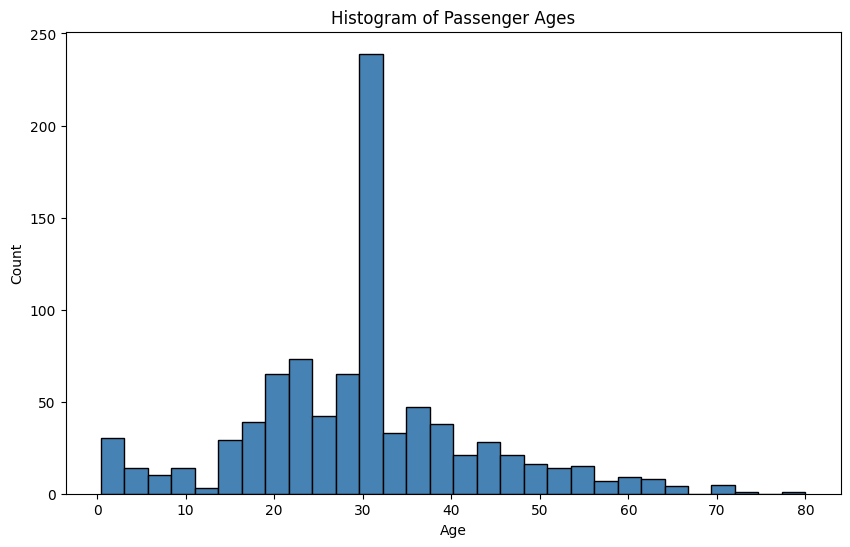

In [25]:
# Histogram of passenger ages
plt.figure(figsize=(10, 6))
plt.hist(df['Age'], bins=30, color='steelblue', edgecolor='black')
plt.title('Histogram of Passenger Ages')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

**Notes:** Most passengers were between 20 and 40 years old. The tall bar near 30 is caused by the 177 missing ages that were filled with the mean (29.7).

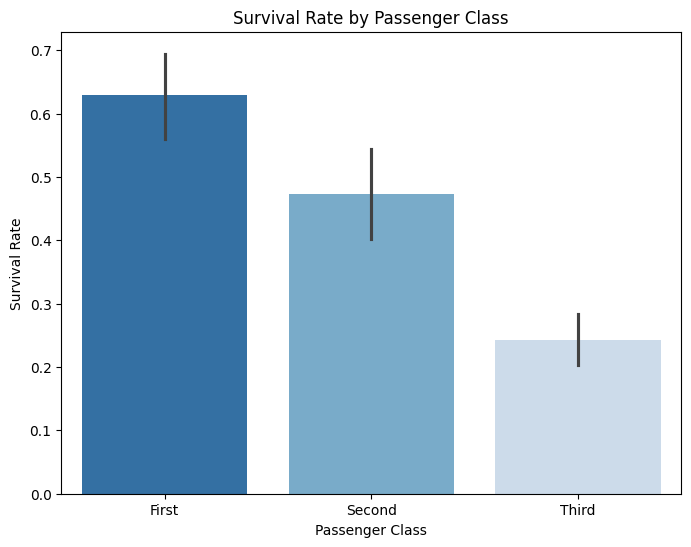

In [26]:
# Bar plot of survival rates by passenger class
plt.figure(figsize=(8, 6))
sns.barplot(x='PclassCategory', y='Survived', data=df, palette='Blues_r', hue='PclassCategory', legend=False)
plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.show()

**Notes:** The survival rate goes down with the class: about **63%** in first class, **47%** in second class and only **24%** in third class.

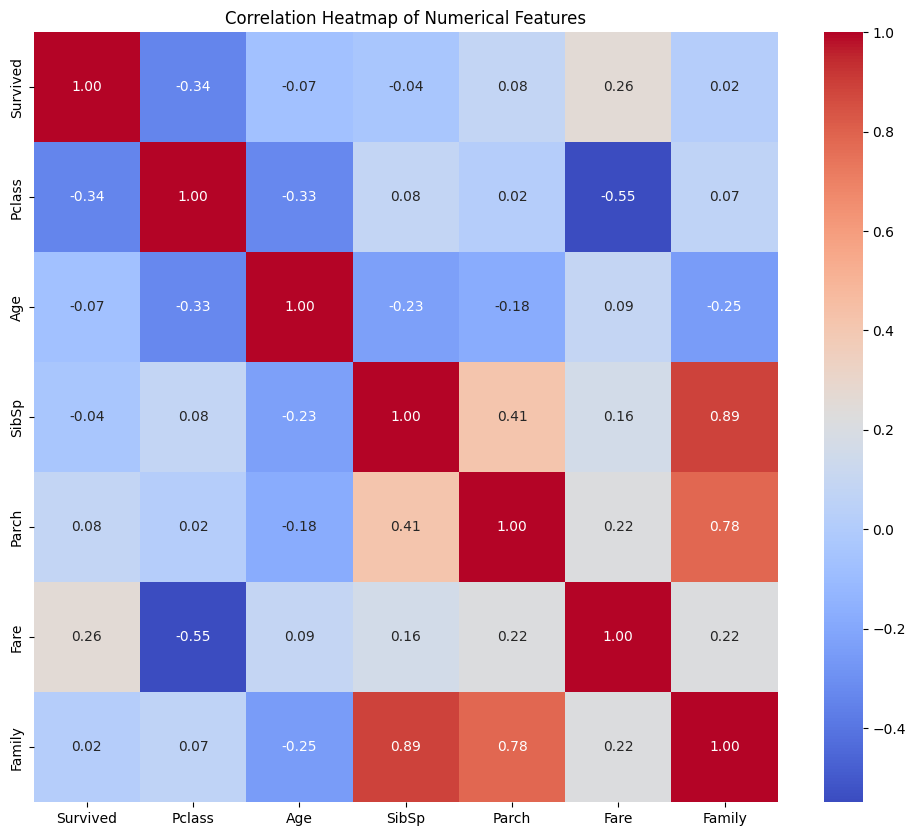

In [27]:
# Heatmap of correlation between numerical features
plt.figure(figsize=(12, 10))
corr = df.select_dtypes(include='number').drop(columns='PassengerId').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Numerical Features')
plt.show()

**Notes:**
- `Pclass` and `Survived` have a negative correlation (**-0.34**): higher class number (third class) = lower survival.
- `Fare` and `Survived` have a positive correlation (**0.26**): passengers who paid more survived more.
- `Pclass` and `Fare` have a strong negative correlation (**-0.55**): first class tickets were more expensive.
- `Family` is highly correlated with `SibSp` (0.89) and `Parch` (0.78) because it was created from them.

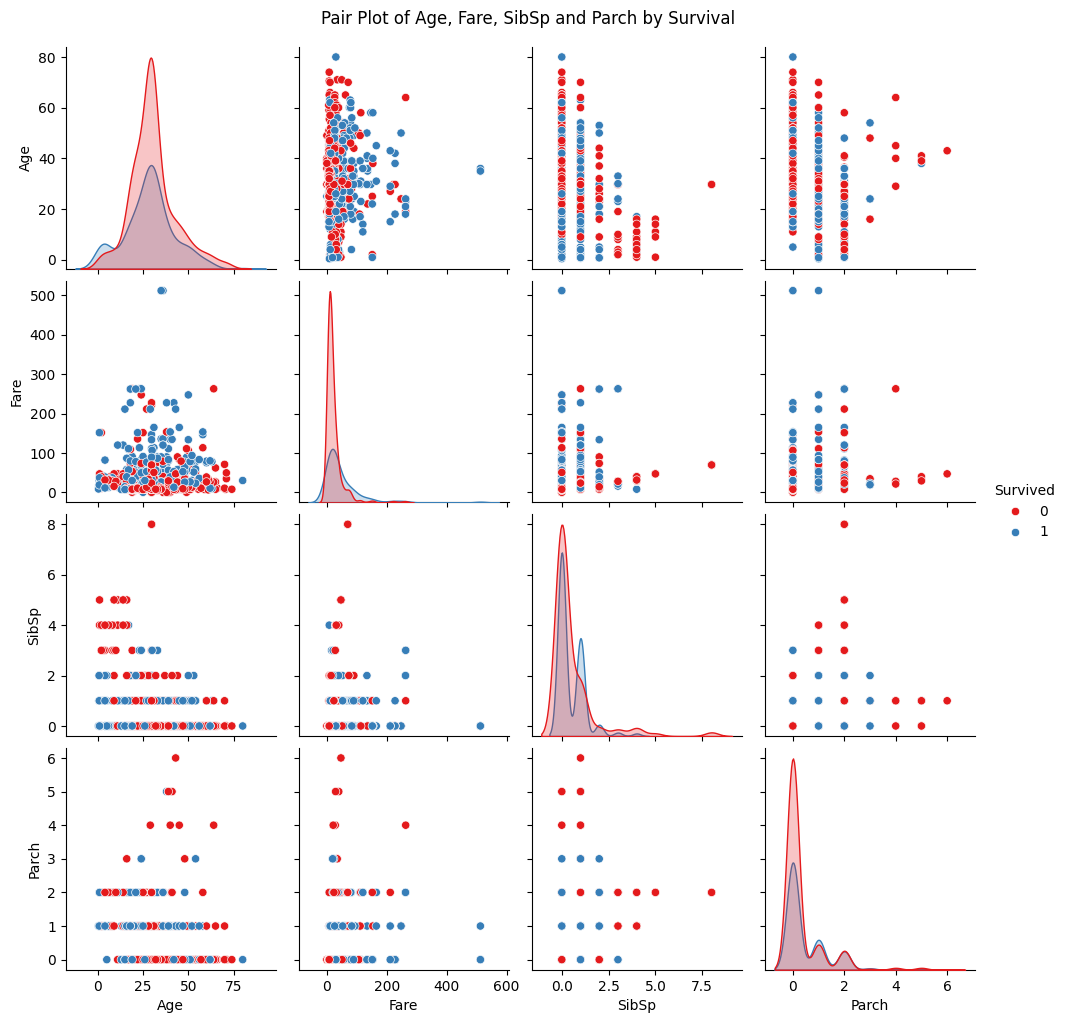

In [28]:
# Pair plot of 'Age', 'Fare', 'SibSp' and 'Parch', colored by 'Survived'
sns.pairplot(df[['Age', 'Fare', 'SibSp', 'Parch', 'Survived']], hue='Survived', palette='Set1')
plt.suptitle('Pair Plot of Age, Fare, SibSp and Parch by Survival', y=1.02)
plt.show()

**Notes:** In the pair plot, the survivors (1) are more common among passengers with higher fares. Passengers with big families (many SibSp or Parch) mostly did not survive.

## Task 8: Analyze survival rates

In [29]:
# Survival rates by sex
survival_by_sex = df.groupby('Sex')['Survived'].mean()
survival_by_sex

,Survived
Sex,
female,0.742038
male,0.188908


In [30]:
# Survival rates by passenger class
survival_by_class = df.groupby('Pclass')['Survived'].mean()
survival_by_class

,Survived
Pclass,
1,0.629630
2,0.472826
3,0.242363


**Notes:**
- **74.2%** of women survived, compared with only **18.9%** of men. This agrees with the "women and children first" rule.
- First class: **63.0%**, second class: **47.3%**, third class: **24.2%**.
- Sex and class were the two most important factors for survival.

## Task 9: Analyze age distribution

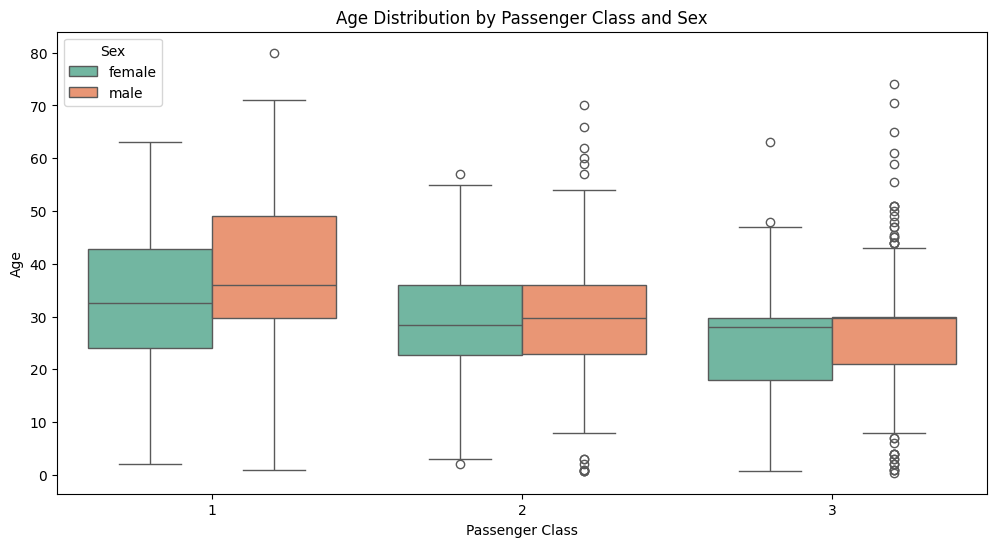

In [31]:
# Box plot of age distribution by passenger class and sex
plt.figure(figsize=(12, 6))
sns.boxplot(x='Pclass', y='Age', hue='Sex', data=df, palette='Set2')
plt.title('Age Distribution by Passenger Class and Sex')
plt.xlabel('Passenger Class')
plt.ylabel('Age')
plt.show()

**Notes:** First class passengers were older (median about 36 for men and 32.5 for women). Second and third class passengers were younger (median close to 28–30). There are some outliers: older passengers in second and third class.

## Task 10: Analyze fare distribution

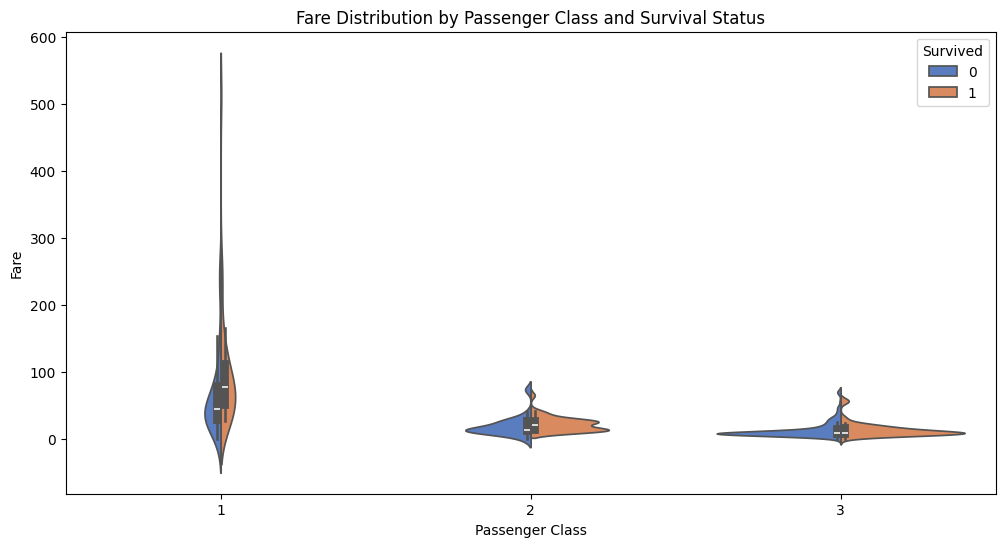

In [32]:
# Violin plot of fare distribution by passenger class and survival status
plt.figure(figsize=(12, 6))
sns.violinplot(x='Pclass', y='Fare', hue='Survived', data=df, split=True, palette='muted')
plt.title('Fare Distribution by Passenger Class and Survival Status')
plt.xlabel('Passenger Class')
plt.ylabel('Fare')
plt.show()

**Notes:** First class fares are much higher and more spread out than second and third class fares. In first class, survivors paid more (median fare about 78) than those who did not survive (about 45). In third class almost everybody paid a low fare (around 8), and the fare made little difference.

In [33]:
print("EDA tasks completed.")

EDA tasks completed.


## Summary of insights from the EDA
1. **Only 38% of the passengers survived** (342 of 891).
2. **Sex was the strongest factor:** 74% of women survived vs 19% of men.
3. **Class mattered a lot:** survival went from 63% in first class to 24% in third class. Women in first and second class had more than 90% survival.
4. **Money and survival are related:** higher fares are linked to higher survival, mainly because expensive tickets were first class.
5. **Large families had low survival:** the biggest family (Sage, 10 relatives, third class) had no survivors.
6. **Data quality:** `Age` had 177 missing values (filled with the mean, 29.7) and `Cabin` had 687 missing values, so the cabin information is limited. Filling Age with the mean creates a peak at 30 in the histogram, so the real age distribution is a bit different.